In [2]:
import pandas as pd

In [3]:
MI_ATAC_morris = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel/MI_label_entropy_morris_atac_50_permutations.csv")
MI_RNA_morris = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel/MI_label_entropy_morris_rna_50_permutations.csv")

In [4]:
print(MI_ATAC_morris.shape)

(163646, 6)


In [5]:
# Assuming MI_RNA_morris and MI_ATAC_morris are dictionaries with numerical values
MI_RNA_values = list(MI_RNA_morris["true_mi"])
MI_ATAC_values = list(MI_ATAC_morris["true_mi"])


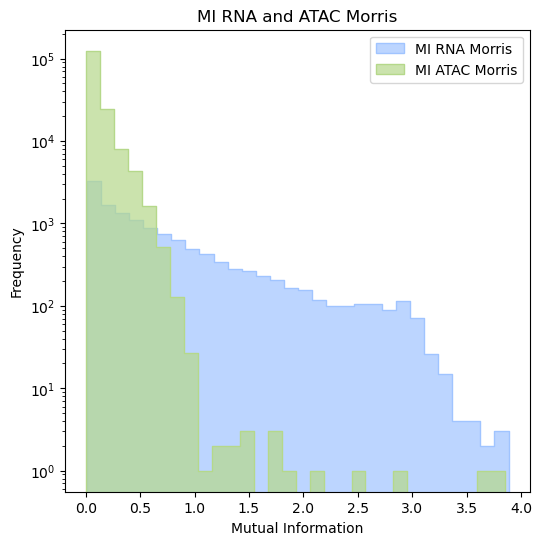

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


# Create figure
plt.figure(figsize=(6, 6))

# Plot both histograms with step=True
sns.histplot(MI_RNA_values, bins=30, color="#a0c4ff", alpha=0.7, element="step", label="MI RNA Morris")
sns.histplot(MI_ATAC_values, bins=30, color='#B5D88A', alpha=0.7, element="step", label="MI ATAC Morris")

# Labels and title
plt.title('MI RNA and ATAC Morris')
plt.xlabel('Mutual Information')
plt.ylabel('Frequency')
plt.yscale('log')  # Set log scale for the y-axis

# Add legend
plt.legend()

# Save figure
plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/MI_RNA_and_ATAC_Morris.pdf", bbox_inches='tight')

# Show plot
plt.show()


In [44]:
MI_ATAC_morris["is_significant"] = MI_ATAC_morris["true_mi"]>MI_ATAC_morris["95_perm_mi"]


In [46]:
import os
import pandas as pd

df = MI_ATAC_morris.copy()

# ---- adapt these two lines to your table ----
region_col = "gene"          # or set to None to use df.index
mi_col = "true_mi"           # or 0 if MI is stored in column 0
sign_col = "is_significant"  # or "p_adj"/"pval" etc (see below)

# If you don't already have a boolean column, create it here, e.g.:
# df["is_significant"] = df["perm_pval"] < 0.05
# df["is_significant"] = df["fdr"] < 0.05

if region_col is None:
    regions = df.index.astype(str).values
else:
    regions = df[region_col].astype(str).values

def parse_to_bed(region):
    chrom, coords = region.split(":")
    start, end = coords.split("-")
    return chrom, int(start), int(end)

bed_data = [parse_to_bed(r) for r in regions]
out = pd.DataFrame(bed_data, columns=["chrom", "start", "end"])
out["mi"] = df[mi_col].astype(float).values
out["is_significant"] = df[sign_col].astype(bool).values

out_path = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/ATAC_master_peaks_MI_sign.tsv"
os.makedirs(os.path.dirname(out_path), exist_ok=True)
out.to_csv(out_path, sep="\t", index=False)

print("Wrote:", out_path)
print(out.head())


Wrote: /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/ATAC_master_peaks_MI_sign.tsv
  chrom    start      end        mi  is_significant
0  chr1  3119540  3120453  0.038449            True
1  chr1  3267991  3268890  0.026619           False
2  chr1  3360536  3361569  0.057657           False
3  chr1  3416004  3416747  0.025079           False
4  chr1  3444651  3445528  0.009860           False


# Checking RNA MI data from ATAC 

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Optional stats annotations
try:
    from statannotations.Annotator import Annotator
    HAS_ANNOT = True
except ImportError:
    HAS_ANNOT = False


# ----------------------------
# CONFIG
# ----------------------------
ATAC_GROUPS_TSV = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/ATAC_master_peaks_MI_sign_ATAC_gene_groups_by_MI_decile.tsv"
OUT_PDF = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/RNA_MI_boxplot_by_ATAC_MI_deciles_plus_background.pdf"

ADD_STATS = True
STAT_TEST = "Mann-Whitney"   # recommended
FDR_CORRECT = True           # correct across the 10 comparisons vs background

FIGSIZE = (9, 4.5)
POINT_ALPHA = 0.15
POINT_SIZE = 2
JITTER = 0.25
SHOW_FLIERS = False


# ----------------------------
# Load ATAC gene groups
# ----------------------------
atac = pd.read_csv(ATAC_GROUPS_TSV, sep="\t")

if not {"gene_symbol", "group"}.issubset(atac.columns):
    raise ValueError(f"ATAC group file must contain gene_symbol and group. Found: {list(atac.columns)}")

atac["gene_symbol"] = atac["gene_symbol"].astype(str)
atac["group"] = atac["group"].astype(str)

group_order = ["Background_non_sign"] + [f"Q{i}" for i in range(1, 11)]
atac = atac[atac["group"].isin(group_order)].copy()


# ----------------------------
# Build RNA MI table from MI_RNA_morris
# ----------------------------
rna = MI_RNA_morris[["gene", "true_mi"]].copy()  # noqa: F821
rna = rna.rename(columns={"gene": "gene_symbol", "true_mi": "rna_mi"})
rna["gene_symbol"] = rna["gene_symbol"].astype(str)

# If there are duplicate genes, keep the maximum RNA MI (or you can use mean)
rna = rna.groupby("gene_symbol", as_index=False)["rna_mi"].max()


# ----------------------------
# Merge
# ----------------------------
plot_df = atac.merge(rna, on="gene_symbol", how="inner")

# Clean
plot_df = plot_df.replace([float("inf"), float("-inf")], pd.NA).dropna(subset=["rna_mi", "group"])

plot_df["group"] = pd.Categorical(plot_df["group"], categories=group_order, ordered=True)
plot_df = plot_df.sort_values("group")

print("Genes in ATAC groups:", atac.shape[0])
print("Genes with RNA MI (after merge):", plot_df.shape[0])
print("Counts per group:\n", plot_df["group"].value_counts().reindex(group_order))

# ----------------------------
# Highlight gene of interest
# ----------------------------
genes_to_highlight = ["Mex3c"]

highlight_df = plot_df[
    plot_df["gene_symbol"].isin(genes_to_highlight)
].copy()

print(highlight_df)

# ----------------------------
# Plot
# ----------------------------
os.makedirs(os.path.dirname(OUT_PDF), exist_ok=True)

plt.figure(figsize=FIGSIZE)

ax = sns.boxplot(
    data=plot_df,
    x="group",
    y="rna_mi",
    showfliers=SHOW_FLIERS
)

sns.stripplot(
    data=plot_df,
    x="group",
    y="rna_mi",
    color="black",
    size=POINT_SIZE,
    alpha=POINT_ALPHA,
    jitter=JITTER
)

# Overlay highlighted gene(s)
sns.scatterplot(
    data=highlight_df,
    x="group",
    y="rna_mi",
    color="#D55E00",      # same red as ATAC significant peaks
    s=90,
    zorder=10,
    edgecolor="black"
)

# Add text label
for _, row in highlight_df.iterrows():
    ax.text(
        x=list(plot_df["group"].cat.categories).index(row["group"]),
        y=row["rna_mi"],
        s=row["gene_symbol"],
        fontsize=9,
        ha="left",
        va="bottom"
    )


ax.grid(False)
sns.despine(ax=ax)

plt.xlabel("")
plt.ylabel("RNA mutual information")
plt.xticks(rotation=60, ha="right")


# ----------------------------
# Optional: statistical annotations (each decile vs background)
# ----------------------------
if ADD_STATS:
    if not HAS_ANNOT:
        print("statannotations not installed; skipping statistical annotations.")
    else:
        pairs = [("Background_non_sign", f"Q{i}") for i in range(1, 11)]
        annotator = Annotator(ax, pairs, data=plot_df, x="group", y="rna_mi", order=group_order)

        cfg = dict(test=STAT_TEST, text_format="star", loc="inside")
        if FDR_CORRECT:
            cfg["comparisons_correction"] = "fdr_bh"

        annotator.configure(**cfg)
        annotator.apply_and_annotate()

plt.tight_layout()
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()

print("Saved:", OUT_PDF)


# only Q10

Genes in ATAC groups (subset): 13422
Genes with RNA MI (after merge): 7444
Counts per group:
 Background_non_sign    6145
Q10                    1299
Name: group, dtype: int64
Highlight rows:
     gene_symbol group  best_atac_mi    rna_mi
668       Mex3c   Q10      0.865987  0.569524
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Background_non_sign vs. Q10: Mann-Whitney-Wilcoxon test two-sided, P_val:6.695e-24 U_stat=3.282e+06


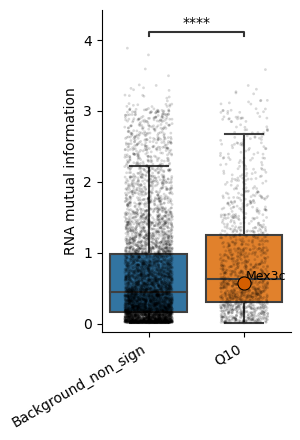

Saved: /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/RNA_MI_boxplot_background_vs_Q10_with_Mex3c.pdf


In [6]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Optional stats annotations
try:
    from statannotations.Annotator import Annotator
    HAS_ANNOT = True
except ImportError:
    HAS_ANNOT = False


# ----------------------------
# CONFIG
# ----------------------------
ATAC_GROUPS_TSV = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/ATAC_master_peaks_MI_sign_ATAC_gene_groups_by_MI_decile.tsv"
OUT_PDF = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/RNA_MI_boxplot_background_vs_Q10_with_Mex3c.pdf"

ADD_STATS = True
STAT_TEST = "Mann-Whitney"
FDR_CORRECT = False  # only one comparison now

FIGSIZE = (3.0, 4.5)
POINT_ALPHA = 0.15
POINT_SIZE = 2
JITTER = 0.25
SHOW_FLIERS = False

# Only show these groups
group_order = ["Background_non_sign", "Q10"]

# Highlight gene(s)
genes_to_highlight = ["Mex3c"]


# ----------------------------
# Load ATAC gene groups
# ----------------------------
atac = pd.read_csv(ATAC_GROUPS_TSV, sep="\t")

if not {"gene_symbol", "group"}.issubset(atac.columns):
    raise ValueError(f"ATAC group file must contain gene_symbol and group. Found: {list(atac.columns)}")

atac["gene_symbol"] = atac["gene_symbol"].astype(str)
atac["group"] = atac["group"].astype(str)

# Keep only Background and Q10
atac = atac[atac["group"].isin(group_order)].copy()


# ----------------------------
# Build RNA MI table from MI_RNA_morris
# ----------------------------
rna = MI_RNA_morris[["gene", "true_mi"]].copy()  # noqa: F821
rna = rna.rename(columns={"gene": "gene_symbol", "true_mi": "rna_mi"})
rna["gene_symbol"] = rna["gene_symbol"].astype(str)

# If there are duplicate genes, keep the maximum RNA MI (or you can use mean)
rna = rna.groupby("gene_symbol", as_index=False)["rna_mi"].max()


# ----------------------------
# Merge
# ----------------------------
plot_df = atac.merge(rna, on="gene_symbol", how="inner")
plot_df = plot_df.replace([float("inf"), float("-inf")], pd.NA).dropna(subset=["rna_mi", "group"])

plot_df["group"] = pd.Categorical(plot_df["group"], categories=group_order, ordered=True)
plot_df = plot_df.sort_values("group")

print("Genes in ATAC groups (subset):", atac.shape[0])
print("Genes with RNA MI (after merge):", plot_df.shape[0])
print("Counts per group:\n", plot_df["group"].value_counts().reindex(group_order))


# ----------------------------
# Highlight gene of interest
# ----------------------------
highlight_df = plot_df[plot_df["gene_symbol"].isin(genes_to_highlight)].copy()
print("Highlight rows:\n", highlight_df)


# ----------------------------
# Plot
# ----------------------------
os.makedirs(os.path.dirname(OUT_PDF), exist_ok=True)

plt.figure(figsize=FIGSIZE)

ax = sns.boxplot(
    data=plot_df,
    x="group",
    y="rna_mi",
    showfliers=SHOW_FLIERS
)

sns.stripplot(
    data=plot_df,
    x="group",
    y="rna_mi",
    color="black",
    size=POINT_SIZE,
    alpha=POINT_ALPHA,
    jitter=JITTER
)

# Overlay highlighted gene(s) (only if present in the filtered groups)
if not highlight_df.empty:
    sns.scatterplot(
        data=highlight_df,
        x="group",
        y="rna_mi",
        color="#D55E00",
        s=90,
        zorder=10,
        edgecolor="black"
    )

    # Add text label slightly offset
    for _, row in highlight_df.iterrows():
        x_pos = list(plot_df["group"].cat.categories).index(row["group"])
        ax.text(
            x=x_pos + 0.02,
            y=row["rna_mi"],
            s=row["gene_symbol"],
            fontsize=9,
            ha="left",
            va="bottom"
        )
else:
    print("Warning: highlighted gene not present in Background/Q10 subset.")

ax.grid(False)
sns.despine(ax=ax)

plt.xlabel("")
plt.ylabel("RNA mutual information")
plt.xticks(rotation=30, ha="right")


# ----------------------------
# Optional stats: Background vs Q10 only
# ----------------------------
if ADD_STATS:
    if not HAS_ANNOT:
        print("statannotations not installed; skipping statistical annotations.")
    else:
        pairs = [("Background_non_sign", "Q10")]
        annotator = Annotator(ax, pairs, data=plot_df, x="group", y="rna_mi", order=group_order)
        annotator.configure(test=STAT_TEST, text_format="star", loc="inside")
        annotator.apply_and_annotate()

plt.tight_layout()
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()

print("Saved:", OUT_PDF)
